Current folder: /content
Landmarks folder exists? True
LANDMARK RECOGNITION USING SIFT - Google Colab Version

TASK 2: Building Landmark Database + SIFT Features

→ colosseum
  ✓ colosseum.jpg: 274 keypoints

→ eiffel_tower
  ✓ eiffel_tower.jpg: 1628 keypoints

→ great_wall
  ✓ great_wall.jpg: 1628 keypoints

→ statue_of_liberty
  ✓ statue_of_liberty.jpg: 1248 keypoints

→ taj_mahal
  ✓ taj_mahal.jpg: 1714 keypoints

✅ Database ready with 5 landmarks

Creating test images (Original / Rotated / Resized / Dark)...

Running evaluation...


Processing Query: colosseum_original.jpg
Query keypoints: 270

Matching Results:
  colosseum            →  267 good matches
  great_wall           →    8 good matches
  statue_of_liberty    →    3 good matches
  taj_mahal            →    2 good matches
  eiffel_tower         →    1 good matches

Predicted          : colosseum
Reliable Matches   : 267
Decision           : ✅ RECOGNIZED
Time               : 0.105 sec
RANSAC Inliers     : 267


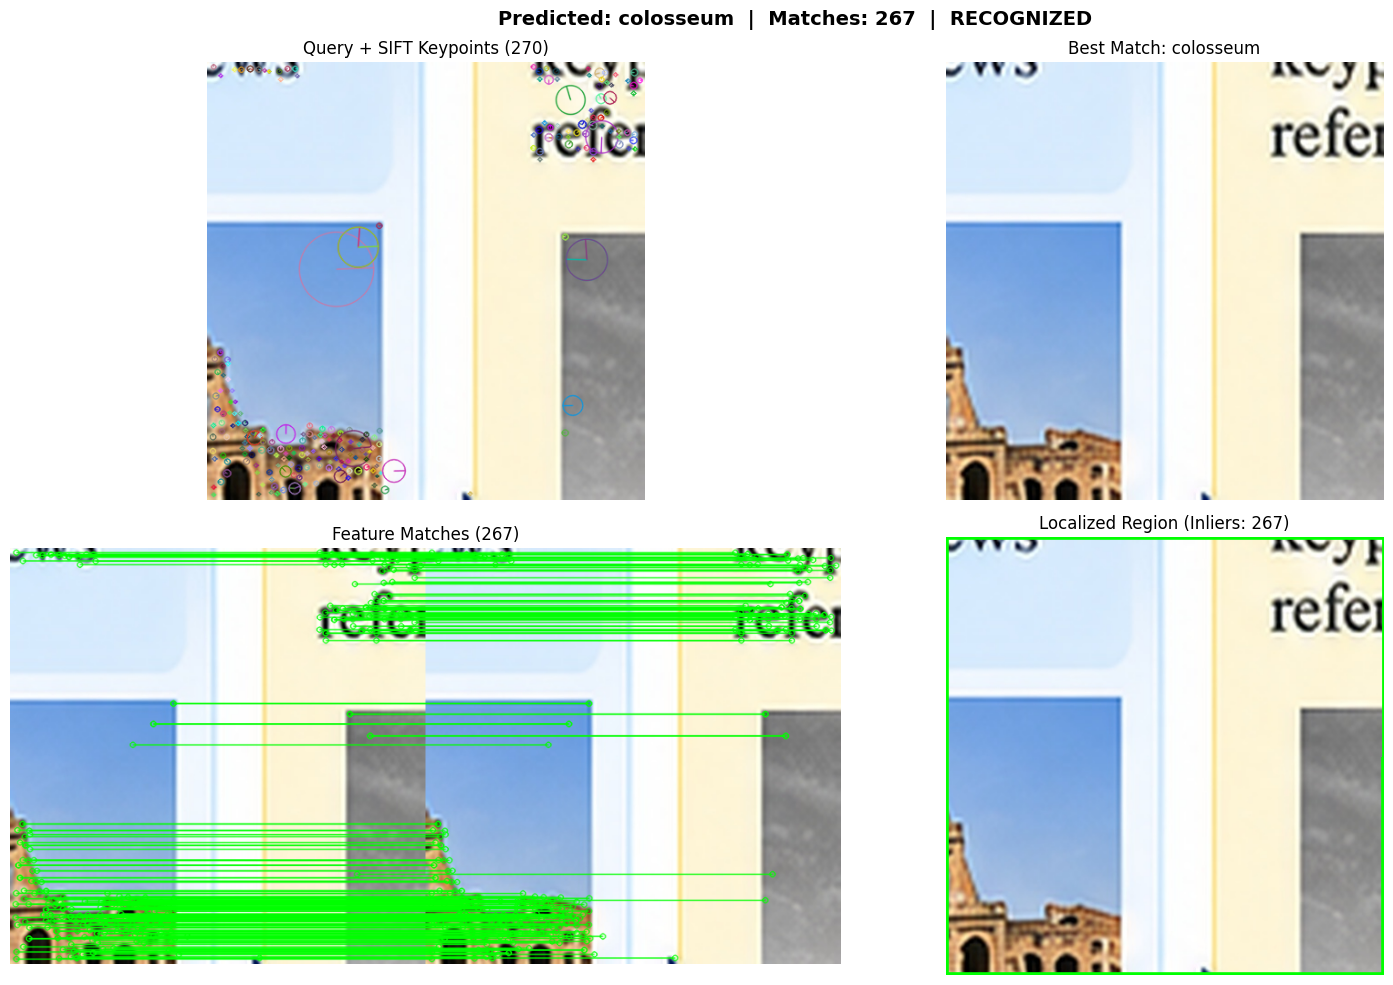


Processing Query: colosseum_rotated.jpg
Query keypoints: 144

Matching Results:
  colosseum            →   87 good matches
  statue_of_liberty    →    5 good matches
  great_wall           →    4 good matches
  eiffel_tower         →    1 good matches
  taj_mahal            →    1 good matches

Predicted          : colosseum
Reliable Matches   : 87
Decision           : ✅ RECOGNIZED
Time               : 0.129 sec
RANSAC Inliers     : 82


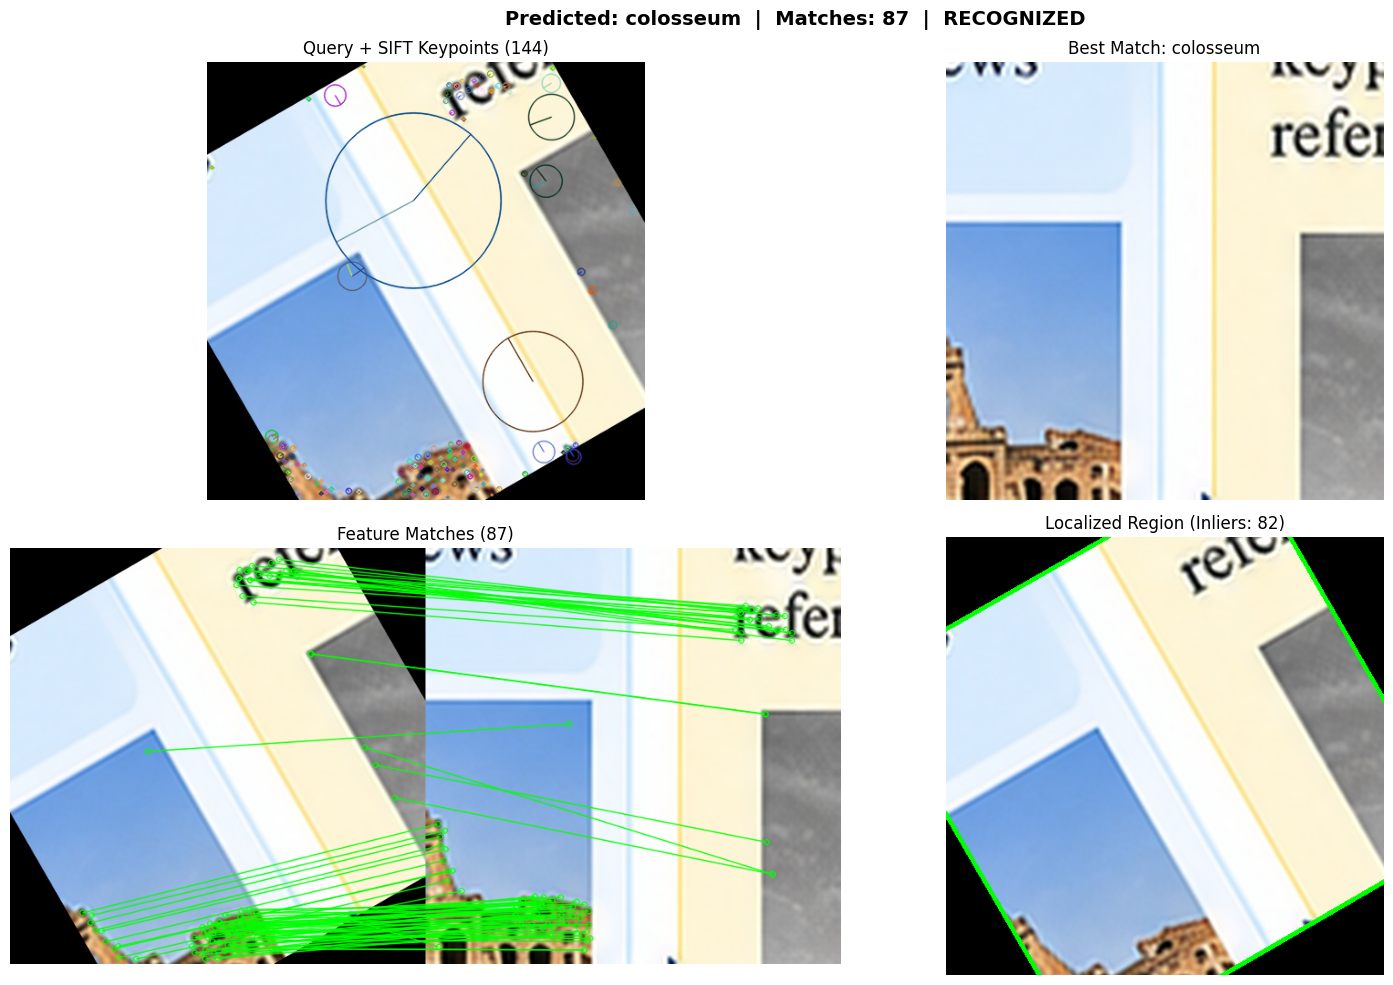


Processing Query: colosseum_resized.jpg
Query keypoints: 266

Matching Results:
  colosseum            →  220 good matches
  great_wall           →    9 good matches
  eiffel_tower         →    3 good matches
  statue_of_liberty    →    2 good matches
  taj_mahal            →    2 good matches

Predicted          : colosseum
Reliable Matches   : 220
Decision           : ✅ RECOGNIZED
Time               : 0.140 sec
RANSAC Inliers     : 215


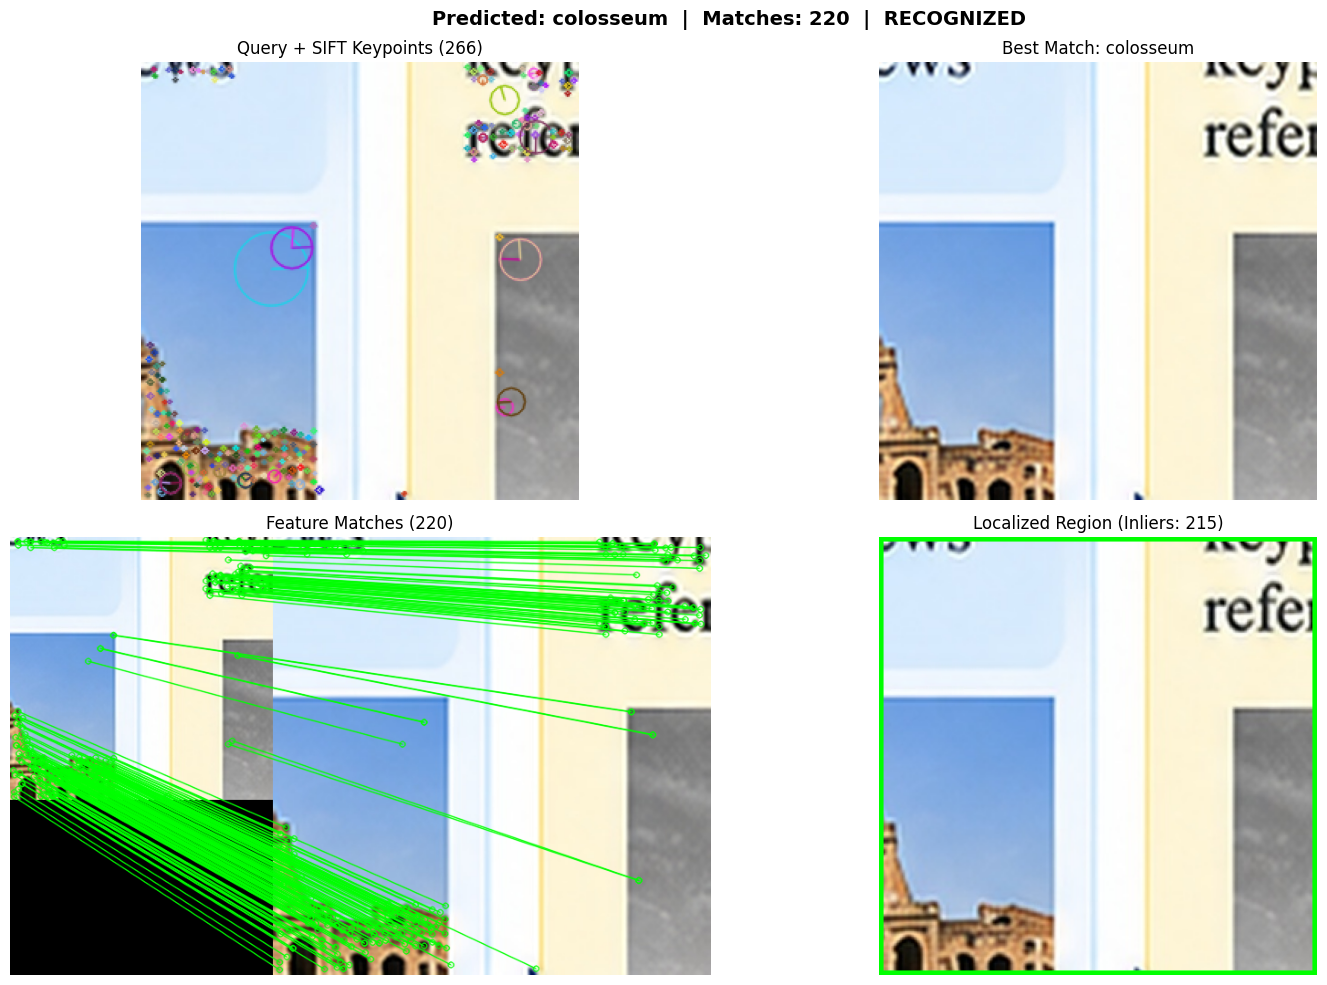


Processing Query: colosseum_dark.jpg
Query keypoints: 233

Matching Results:
  colosseum            →   94 good matches
  great_wall           →    6 good matches
  eiffel_tower         →    3 good matches
  statue_of_liberty    →    3 good matches
  taj_mahal            →    1 good matches

Predicted          : colosseum
Reliable Matches   : 94
Decision           : ✅ RECOGNIZED
Time               : 0.148 sec
RANSAC Inliers     : 90


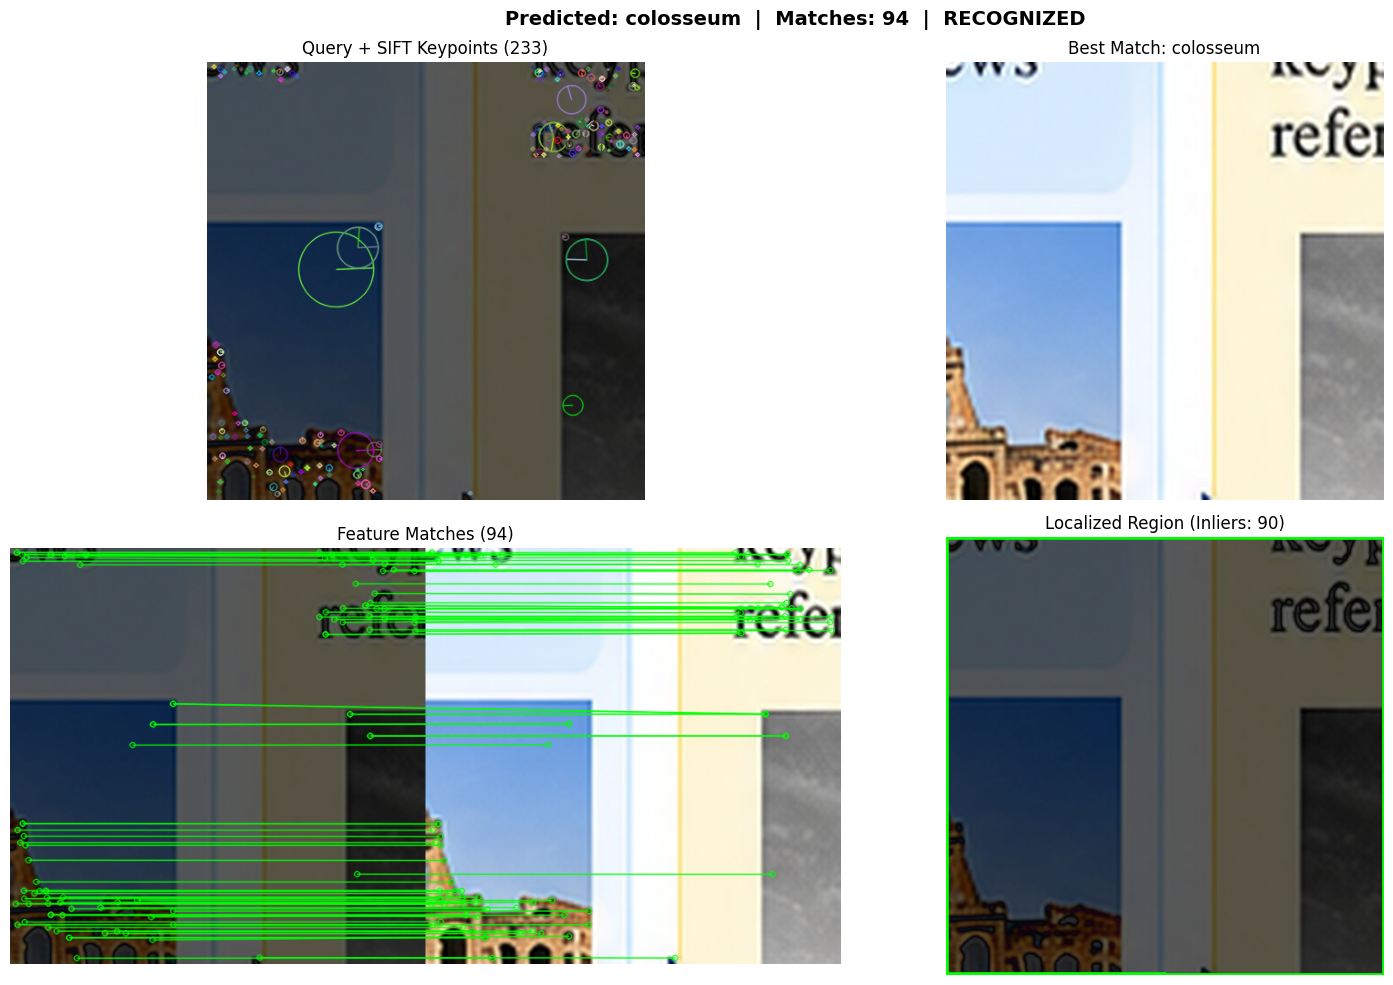


Creating Extra Tests (Viewpoint + Unknown)...

Running Extra Evaluation...


Processing Query: colosseum_viewpoint.jpg
Query keypoints: 270

Matching Results:
  colosseum            →  267 good matches
  great_wall           →    8 good matches
  statue_of_liberty    →    3 good matches
  taj_mahal            →    2 good matches
  eiffel_tower         →    1 good matches

Predicted          : colosseum
Reliable Matches   : 267
Decision           : ✅ RECOGNIZED
Time               : 0.149 sec
RANSAC Inliers     : 267


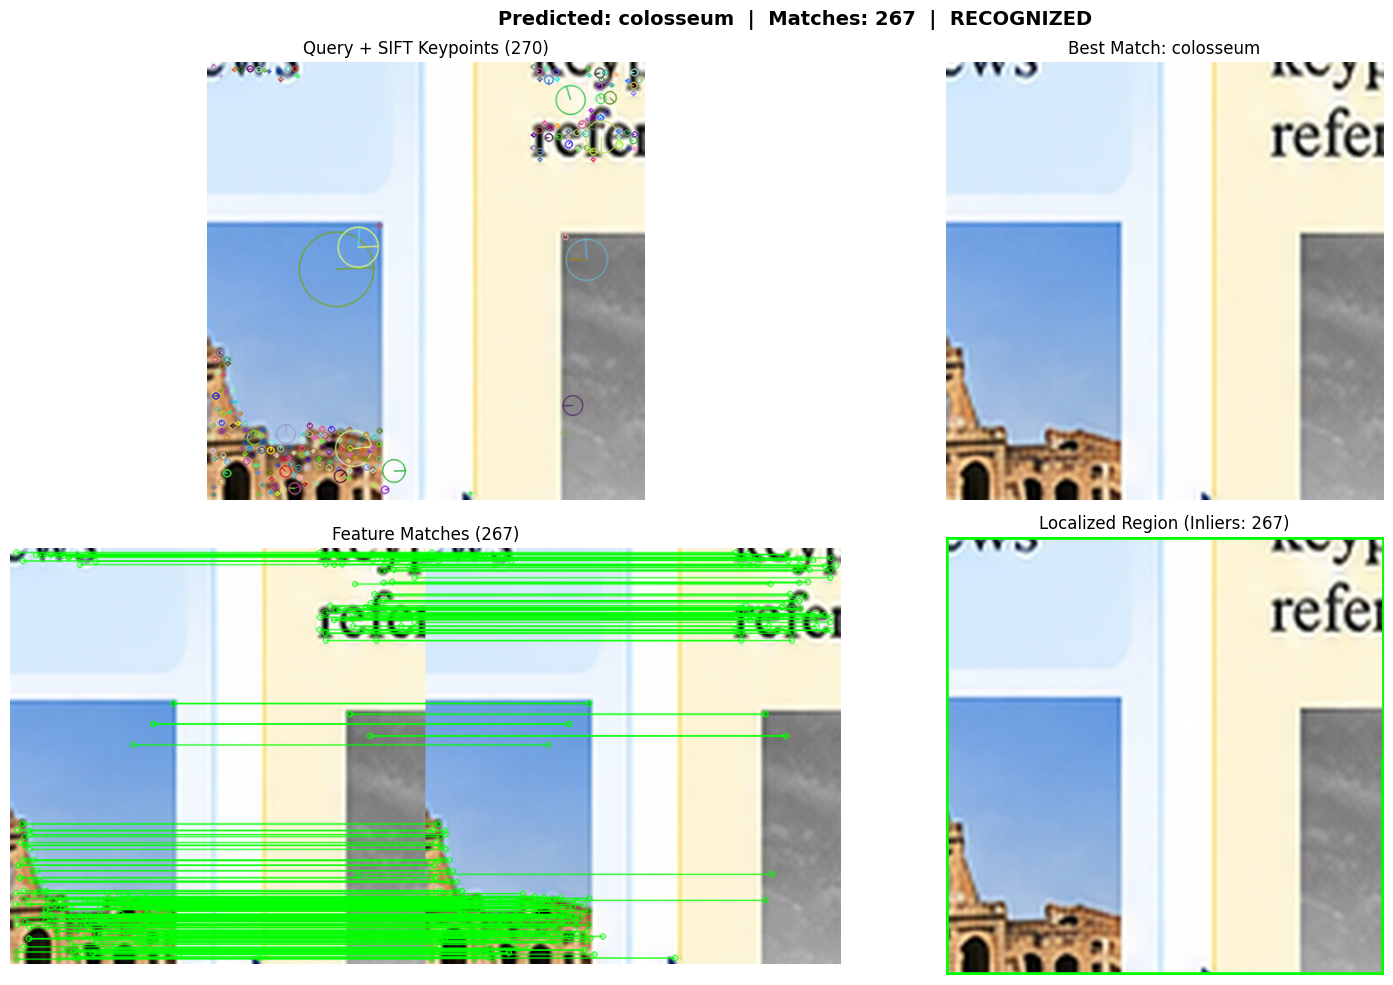


Processing Query: unknown_landmark.jpg
Query keypoints: 62

Matching Results:
  taj_mahal            →    1 good matches
  colosseum            →    0 good matches
  eiffel_tower         →    0 good matches
  great_wall           →    0 good matches
  statue_of_liberty    →    0 good matches

Predicted          : taj_mahal
Reliable Matches   : 1
Decision           : ❌ REJECTED
Time               : 0.079 sec


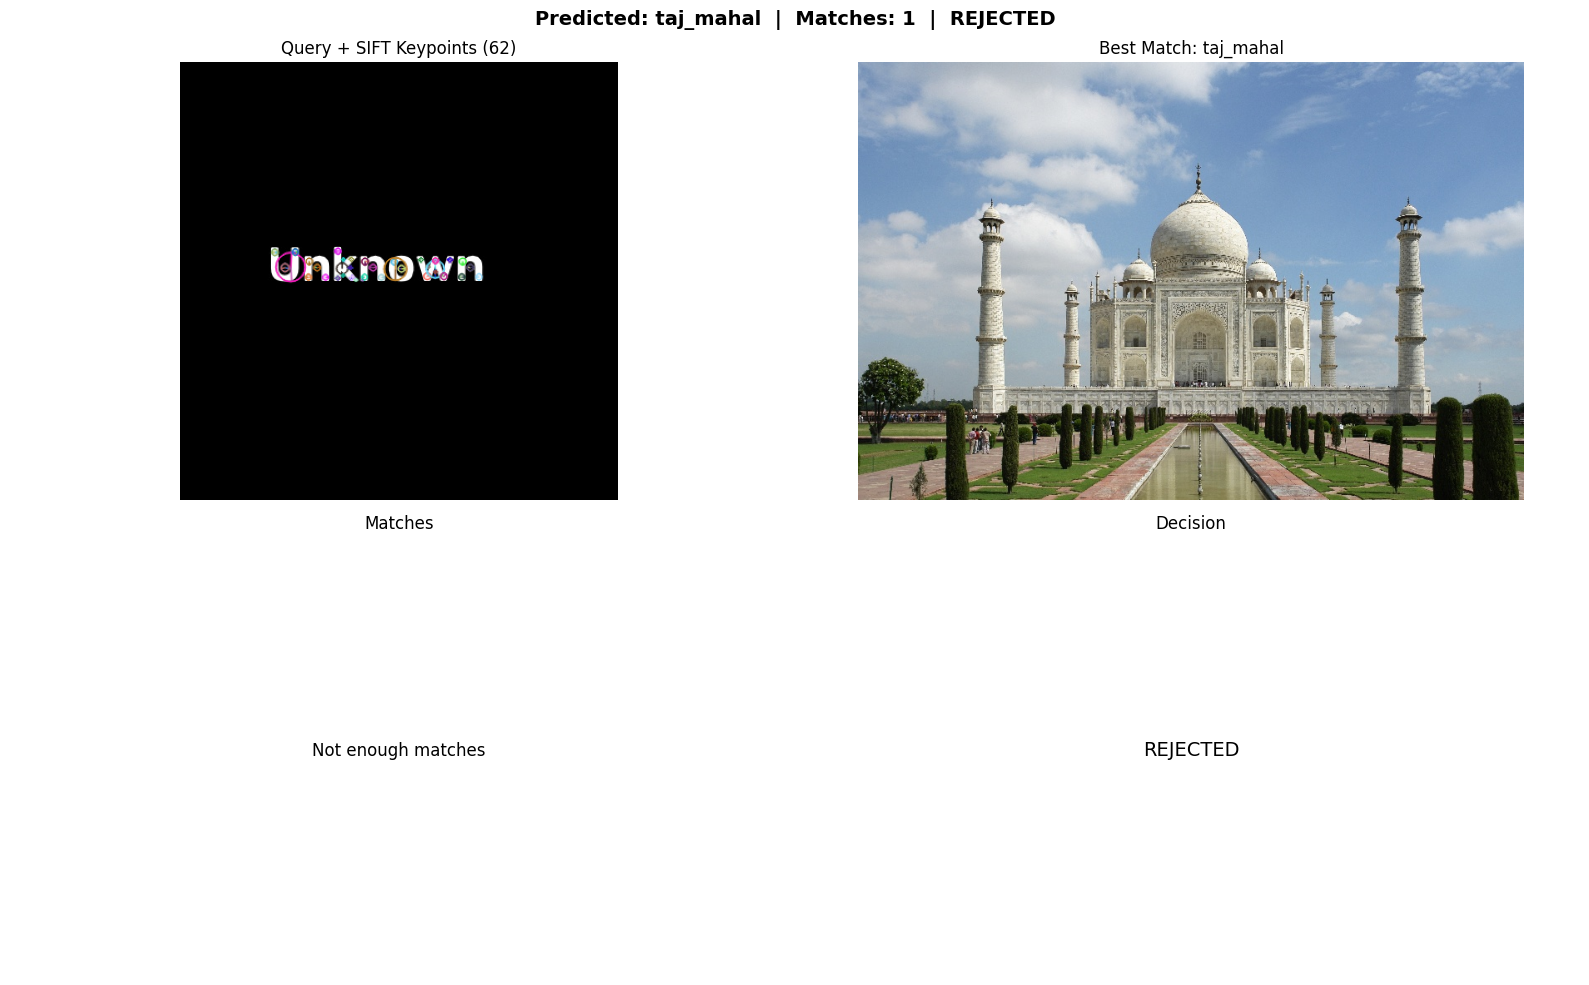


 All tasks completed successfully!


In [7]:
!pip install opencv-python matplotlib -q
import zipfile
from pathlib import Path


LANDMARKS_DIR = "colab_landmarks"
zip_path = Path("colab_landmarks (2).zip")

if not Path(LANDMARKS_DIR).exists():
    if zip_path.exists():
        print(f"📦 Extracting {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")

        if Path("colab_landmarks").exists():
            print("Extraction complete!")
        else:

            extracted_dirs = [p for p in Path(".").iterdir() if p.is_dir() and "landmarks" in p.name.lower()]
            if extracted_dirs and extracted_dirs[0].name != LANDMARKS_DIR:
                extracted_dirs[0].rename(LANDMARKS_DIR)
                print(f"✅ Renamed {extracted_dirs[0].name} to {LANDMARKS_DIR}")
    else:
        print(f"Zip file '{zip_path}' not found. Please upload it first!")

import cv2
import numpy as np
import os
import time
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

MIN_MATCH_COUNT = 12
RATIO_TEST = 0.75
RANSAC_REPROJ_THRESH = 5.0

print("Current folder:", Path('.').resolve())
print("Landmarks folder exists?", Path(LANDMARKS_DIR).exists())

def load_and_preprocess(image_path):
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not load: {image_path}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img, gray

def extract_sift(gray, sift):
    kp, des = sift.detectAndCompute(gray, None)
    return kp, des

def draw_keypoints(img, kp):
    return cv2.drawKeypoints(img, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

def lowe_ratio_test(matches, ratio=RATIO_TEST):
    good = []
    for m, n in matches:
        if m.distance < ratio * n.distance:
            good.append(m)
    return good

def build_database(sift):
    database = {}
    print("\n" + "="*60)
    print("TASK 2: Building Landmark Database + SIFT Features")
    print("="*60)

    if not Path(LANDMARKS_DIR).exists():
        raise FileNotFoundError(f"Directory '{LANDMARKS_DIR}' does not exist. Please check your zip file.")

    for folder in sorted(Path(LANDMARKS_DIR).iterdir()):
        if not folder.is_dir():
            continue
        name = folder.name
        database[name] = []
        print(f"\n→ {name}")

        for img_path in list(folder.glob("*.jpg")) + list(folder.glob("*.png")):
            try:
                color, gray = load_and_preprocess(img_path)
                kp, des = extract_sift(gray, sift)
                if des is None or len(kp) < 5:
                    print(f"  Skipping {img_path.name} (too few keypoints)")
                    continue
                database[name].append({
                    "kp": kp,
                    "des": des,
                    "img": color,
                    "path": str(img_path)
                })
                print(f"  ✓ {img_path.name}: {len(kp)} keypoints")
            except Exception as e:
                print(f"  Error {img_path.name}: {e}")

    total = sum(1 for v in database.values() if v)
    print(f"\n✅ Database ready with {total} landmarks")
    return database

def recognize(query_path, database, sift, bf):
    start = time.time()
    print("\n" + "="*60)
    print(f"Processing Query: {Path(query_path).name}")
    print("="*60)

    q_color, q_gray = load_and_preprocess(query_path)
    q_kp, q_des = extract_sift(q_gray, sift)
    print(f"Query keypoints: {len(q_kp)}")

    results = []
    for name, refs in database.items():
        if not refs: continue
        best_good = 0
        best_matches = None
        best_ref = None

        for ref in refs:
            matches = bf.knnMatch(q_des, ref["des"], k=2)
            good = lowe_ratio_test(matches)
            if len(good) > best_good:
                best_good = len(good)
                best_matches = good
                best_ref = ref

        results.append({
            "name": name,
            "matches": best_good,
            "good": best_matches,
            "ref": best_ref
        })

    results.sort(key=lambda x: x["matches"], reverse=True)

    print("\nMatching Results:")
    for r in results:
        print(f"  {r['name']:20s} → {r['matches']:4d} good matches")

    best = results[0]
    recognized = best["matches"] >= MIN_MATCH_COUNT
    elapsed = time.time() - start

    print(f"\nPredicted          : {best['name']}")
    print(f"Reliable Matches   : {best['matches']}")
    print(f"Decision           : {'✅ RECOGNIZED' if recognized else '❌ REJECTED'}")
    print(f"Time               : {elapsed:.3f} sec")

    plt.figure(figsize=(16, 10))

    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(draw_keypoints(q_color, q_kp), cv2.COLOR_BGR2RGB))
    plt.title(f"Query + SIFT Keypoints ({len(q_kp)})")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    if best["ref"] is not None:
        plt.imshow(cv2.cvtColor(best["ref"]["img"], cv2.COLOR_BGR2RGB))
        plt.title(f"Best Match: {best['name']}")
    plt.axis("off")

    localized = None
    inliers = 0
    match_img = None

    if recognized and best["good"] is not None:
        ref = best["ref"]
        src = np.float32([ref["kp"][m.trainIdx].pt for m in best["good"]]).reshape(-1,1,2)
        dst = np.float32([q_kp[m.queryIdx].pt for m in best["good"]]).reshape(-1,1,2)

        H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_REPROJ_THRESH)
        if H is not None:
            inliers = int(mask.sum())
            print(f"RANSAC Inliers     : {inliers}")

            h, w = ref["img"].shape[:2]
            corners = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
            proj = cv2.perspectiveTransform(corners, H)
            localized = q_color.copy()
            cv2.polylines(localized, [np.int32(proj)], True, (0,255,0), 3)

            match_img = cv2.drawMatches(q_color, q_kp, ref["img"], ref["kp"],
                                        best["good"], None,
                                        matchColor=(0,255,0),
                                        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    plt.subplot(2, 2, 3)
    if match_img is not None:
        plt.imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Feature Matches ({best['matches']})")
    else:
        plt.text(0.5, 0.5, "Not enough matches", ha="center", fontsize=12)
        plt.title("Matches")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    if localized is not None:
        plt.imshow(cv2.cvtColor(localized, cv2.COLOR_BGR2RGB))
        plt.title(f"Localized Region (Inliers: {inliers})")
    else:
        status = "REJECTED" if not recognized else "Localization failed"
        plt.text(0.5, 0.5, status, ha="center", fontsize=14)
        plt.title("Decision")
    plt.axis("off")

    plt.suptitle(f"Predicted: {best['name']}  |  Matches: {best['matches']}  |  {'RECOGNIZED' if recognized else 'REJECTED'}",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    return {
        "predicted": best["name"],
        "matches": best["matches"],
        "recognized": recognized,
        "time": elapsed
    }

def create_extra_tests(database):
    """Extra tests: Different Viewpoint + Unknown Landmark"""
    os.makedirs("query_images", exist_ok=True)
    extra_paths = []

    for name, refs in database.items():
        if refs:
            p = f"query_images/{name}_viewpoint.jpg"
            cv2.imwrite(p, refs[0]["img"])
            extra_paths.append(p)
            break

    unknown = np.zeros((400, 400, 3), dtype=np.uint8)
    cv2.putText(unknown, "Unknown", (80, 200), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255,255,255), 3)
    p = "query_images/unknown_landmark.jpg"
    cv2.imwrite(p, unknown)
    extra_paths.append(p)

    return extra_paths

def create_variants(img_path):
    img = cv2.imread(str(img_path))
    name = Path(img_path).stem
    os.makedirs("query_images", exist_ok=True)
    paths = []

    p = f"query_images/{name}_original.jpg"
    cv2.imwrite(p, img)
    paths.append(p)

    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w//2, h//2), 30, 1.0)
    rot = cv2.warpAffine(img, M, (w, h))
    p = f"query_images/{name}_rotated.jpg"
    cv2.imwrite(p, rot)
    paths.append(p)

    res = cv2.resize(img, None, fx=0.6, fy=0.6)
    p = f"query_images/{name}_resized.jpg"
    cv2.imwrite(p, res)
    paths.append(p)

    dark = cv2.convertScaleAbs(img, alpha=0.5, beta=-40)
    p = f"query_images/{name}_dark.jpg"
    cv2.imwrite(p, dark)
    paths.append(p)

    return paths

print("="*70)
print("LANDMARK RECOGNITION USING SIFT - Google Colab Version")
print("="*70)

sift = cv2.SIFT_create()
bf = cv2.BFMatcher(cv2.NORM_L2)

try:
    database = build_database(sift)
except FileNotFoundError as e:
    print(f"\n ERROR: {e}")
    database = {}

if not any(database.values()):
    print("\n ERROR: No images found in colab_landmarks/")
else:
    sample = None
    for refs in database.values():
        if refs:
            sample = refs[0]["path"]
            break

    print("\nCreating test images (Original / Rotated / Resized / Dark)...")
    test_imgs = create_variants(sample)

    print("\nRunning evaluation...\n")
    for q in test_imgs:
        recognize(q, database, sift, bf)

print("\nCreating Extra Tests (Viewpoint + Unknown)...")
extra_imgs = create_extra_tests(database)

print("\nRunning Extra Evaluation...\n")
for q in extra_imgs:
    recognize(q, database, sift, bf)

print("\n All tasks completed successfully!")